In [2]:
import xarray as xr

from edelassim.observations import valid_snow_cover_fraction_s2, valid_snow_cover_fraction_viirs_mf
from edelassim.snowlines import find_snowline_from_snow_penalization
from edelassim.visualization.static_files import (
    get_snowlines,
    get_spatial_datasets,
    topography_data_folder,
    s2_path,
    viirs_file,
    forest_mask_path,
)
from xarray.groupers import BinGrouper, UniqueGrouper
import numpy as np
from mountain_data_binner.mountain_binner import MountainBinner, MountainBinnerConfig
from ndsi_fsc_calibration.snow_cover_products import S2_CLASSES
from edelassim.observations import METEOFRANCE_CLASSES


# def valid_snow_cover_fraction_viirs_mf_clouds(viirs_mf_data: xr.DataArray) -> xr.DataArray:
#     # satellite_fsc_data = viirs_mf_data.where(viirs_mf_data != METEOFRANCE_CLASSES["water"], 0)
#     valid_data_mask = viirs_mf_data < METEOFRANCE_CLASSES["water"]
#     valid_snow_cover_fraction = viirs_mf_data.where(
#         valid_data_mask, viirs_mf_data / METEOFRANCE_CLASSES["snow_cover"][-1], viirs_mf_data
#     )
#     return valid_snow_cover_fraction


# def valid_snow_cover_fraction_s2_clouds(sentinel2_fsc_data: xr.DataArray) -> xr.DataArray:
#     valid_data_mask = sentinel2_fsc_data < S2_CLASSES["clouds"]
#     valid_snow_cover_fraction = sentinel2_fsc_data.where(valid_data_mask, sentinel2_fsc_data / S2_CLASSES["snow_cover"][-1], sentinel2_fsc_data)
#     return valid_snow_cover_fraction


_, _, snowline_viirs_ds, snowline_s2_ds = get_snowlines(actual_xpid="assim_viirs_cloudcover07_wy2122_d93_50cm")
# forest_mask = xr.open_dataset(forest_mask_path).data_vars["__xarray_dataarray_variable__"].sel(band=1)
viirs = xr.open_dataset(viirs_file)
s2 = xr.open_dataset(s2_path)
dem_250m = xr.open_dataarray(f"{topography_data_folder}/250m/DEM_GR_L93_250m.tif").sel(band=1)
dem_20m = xr.open_dataarray(f"{topography_data_folder}/20m/DEM_GR_UTM_20m.tif").sel(band=1)
aspect_250m = xr.open_dataarray(f"{topography_data_folder}/250m/ASP_GR_L93_250m.tif").sel(band=1)
aspect_20m = xr.open_dataarray(f"{topography_data_folder}/20m/ASP_GR_UTM_20m.tif").sel(band=1)
slope_250m = xr.open_dataarray(f"{topography_data_folder}/250m/SLP_GR_L93_250m.tif").sel(band=1)
slope_20m = xr.open_dataarray(f"{topography_data_folder}/20m/SLP_GR_UTM_20m.tif").sel(band=1)


sl_s2_precalc = find_snowline_from_snow_penalization(snowline_s2_ds)
sl_viirs_precalc = find_snowline_from_snow_penalization(snowline_viirs_ds)

snowline_s2_ds = snowline_s2_ds.set_xindex("altitude_min")
snowline_viirs_ds = snowline_viirs_ds.set_xindex("altitude_min")

In [ ]:
from mountain_data_binner.mountain_binner import MountainBinner

from edelassim.snowlines import snowline_penalization_function, sum_all_values_above, sum_all_values_below

# def count_pixels_per_class(data: xr.Dataset, classes: dict[str, int | range]) -> xr.DataArray:
#     fsc = data.data_vars["snow_cover_fraction"]
#     n_clouds = (fsc == classes["clouds"]).sum()
#     n_snowfree = (fsc <= classes["snow_cover"][-1]/2).sum()
#     n_snow = ((fsc <= classes["snow_cover"][-1]) * (fsc >= classes["snow_cover"][0])).sum()
#     return xr.DataArray(
#         data=[n_clouds, n_snowfree, n_snow], dims=("type",), coords={"type": ["clouds", "no_snow", "snow_cover"]}
#     )


def count_pixels_per_class(data: xr.Dataset, classes: dict) -> xr.DataArray:
    snow_cover_data = data.data_vars["snow_cover_fraction"].unstack()
    snow_cover_mask = snow_cover_data <= classes["snow_cover"][-1]
    snow_cover_fraction = snow_cover_data.where(snow_cover_mask) / classes["snow_cover"][-1]

    # snow_cover_mask = snow_cover_fraction >= 0.5
    return xr.Dataset(
        {
            "snow_cover_sum": (snow_cover_fraction >= 0.5).sum(dim=("x", "y")),
            "land_sum": (snow_cover_fraction < 0.5).sum(dim=("x", "y")),
            "total_clouds": (snow_cover_data == classes["clouds"]).sum(dim=("x", "y")),
        }
    )


def date_count(data: xr.Dataset, classes: dict) -> xr.DataArray:
    count_data = data.groupby(
        {"elevation": BinGrouper(np.arange(650, 3150, 100)), "aspect": MountainBinner.regular_8_aspect_bins()}
    ).map(count_pixels_per_class, classes=classes)
    elevation_min = [bin.left for bin in count_data.elevation_bins.values]
    elevation_max = [bin.right for bin in count_data.elevation_bins.values]
    count_data = count_data.assign_coords({"elevation_min": ("elevation_bins", elevation_min)})
    count_data = count_data.assign_coords({"elevation_max": ("elevation_bins", elevation_max)})
    count_data = count_data.set_xindex("elevation_min")
    lower_snow_sum = sum_all_values_below(count_data["snow_cover_sum"], dim="elevation_bins", coord="elevation_min")
    higher_land_sum = sum_all_values_above(count_data["land_sum"], dim="elevation_bins", coord="elevation_min")
    snowline_metrics = higher_land_sum + lower_snow_sum

    return count_data.assign(
        {"snowline_penalization": snowline_metrics, "lower_snow_sum": lower_snow_sum, "higher_land_sum": higher_land_sum}
    )


In [160]:
# grouped_dataset_s2 = xr.Dataset({"s2": s2.data_vars["snow_cover_fraction"], "elevation": dem_20m}).sel(time="2021-11")
grouped_dataset_s2 = (
    (
        s2.assign({"elevation": dem_20m, "aspect": MountainBinner.aspect_map_transform(aspect_20m)})
        .sel(time=slice("2021-11-01", "2022-02"))
        .drop_vars(("spatial_ref", "band"))
    )
    .where(slope_20m > 8)
    .where(slope_20m < 30)
)
result_s2 = grouped_dataset_s2.groupby("time").map(date_count, classes=S2_CLASSES)
grouped_dataset_viirs = (
    (
        viirs.assign({"elevation": dem_250m, "aspect": MountainBinner.aspect_map_transform(aspect_250m)})
        .sel(time=slice("2021-11-01", "2022-02"))
        .drop_vars(("spatial_ref", "band"))
    )
    .where(slope_250m > 8)
    .where(slope_250m < 30)
)
result_viirs = grouped_dataset_viirs.groupby("time").map(date_count, classes=METEOFRANCE_CLASSES)


snowline_s2_ds = snowline_s2_ds.sel(altitude_min=result_s2.coords["elevation_min"].values)
snowline_viirs_ds = snowline_viirs_ds.sel(altitude_min=result_viirs.coords["elevation_min"].values)


# result_s2.swap_dims({'elevation_bins': 'elevation_min'}).drop_vars('elevation_bins').to_netcdf('s2_count.nc')
# result_viirs.swap_dims({'elevation_bins': 'elevation_min'}).drop_vars('elevation_bins').to_netcdf('viirs_count.nc')

In [ ]:
result_s2.swap_dims({"elevation_bins": "elevation_min"}).drop_vars("elevation_bins").to_netcdf("result_s2_thr05.nc")
result_viirs.swap_dims({"elevation_bins": "elevation_min"}).drop_vars("elevation_bins").to_netcdf("result_viirs_thr05.nc")

In [ ]:
def plot_snow_cloud_vs_elevation_bars(plot_data: xr.DataArray, ax: Axes):
    clouds = plot_data.data_vars["total_clouds"]
    no_snow = plot_data.data_vars["land_sum"]
    snow = plot_data.data_vars["snow_cover_sum"]
    y_ticks = (plot_data.coords["elevation_min"] + plot_data.coords["elevation_max"]) / 2
    ax.barh(y=y_ticks, width=clouds, height=80, color="gray", label="clouds")
    ax.barh(y=y_ticks, width=no_snow, left=clouds, height=80, color="black", label="no snow")
    ax.barh(y=y_ticks, width=snow, left=clouds + no_snow, height=80, color="blue", label="snow")


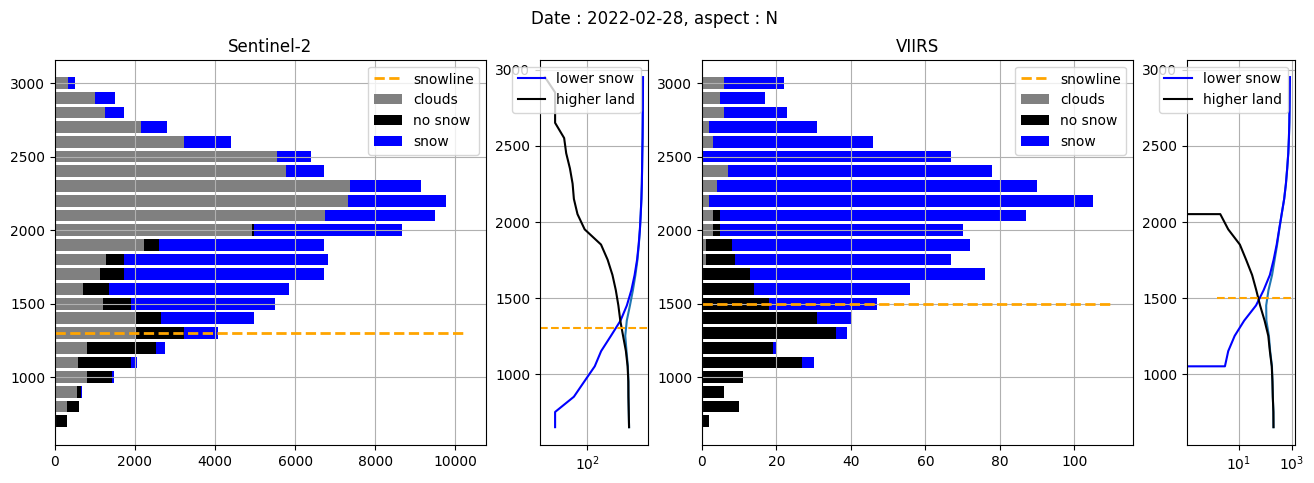

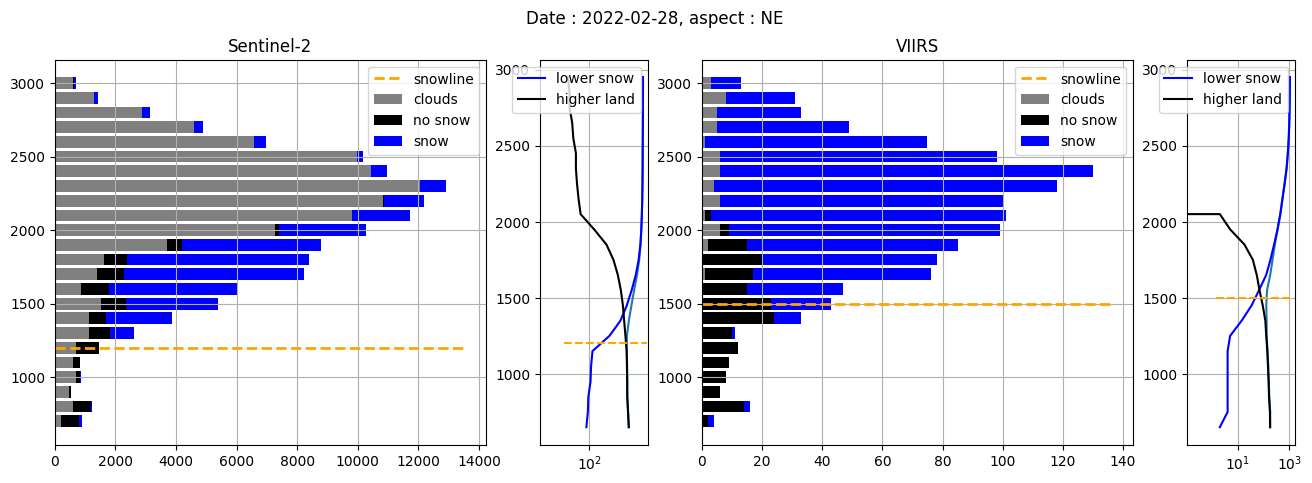

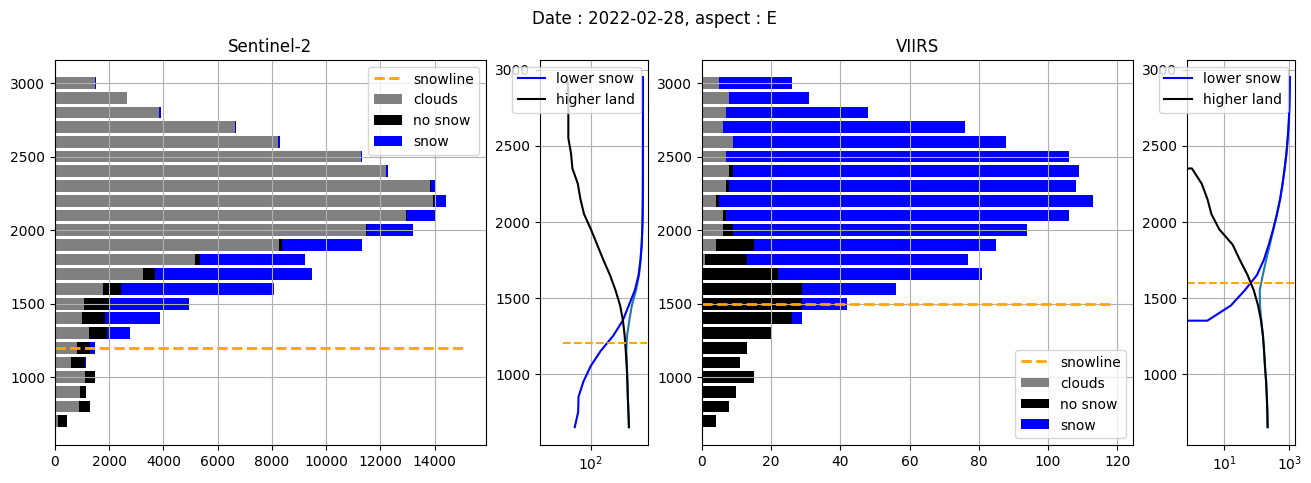

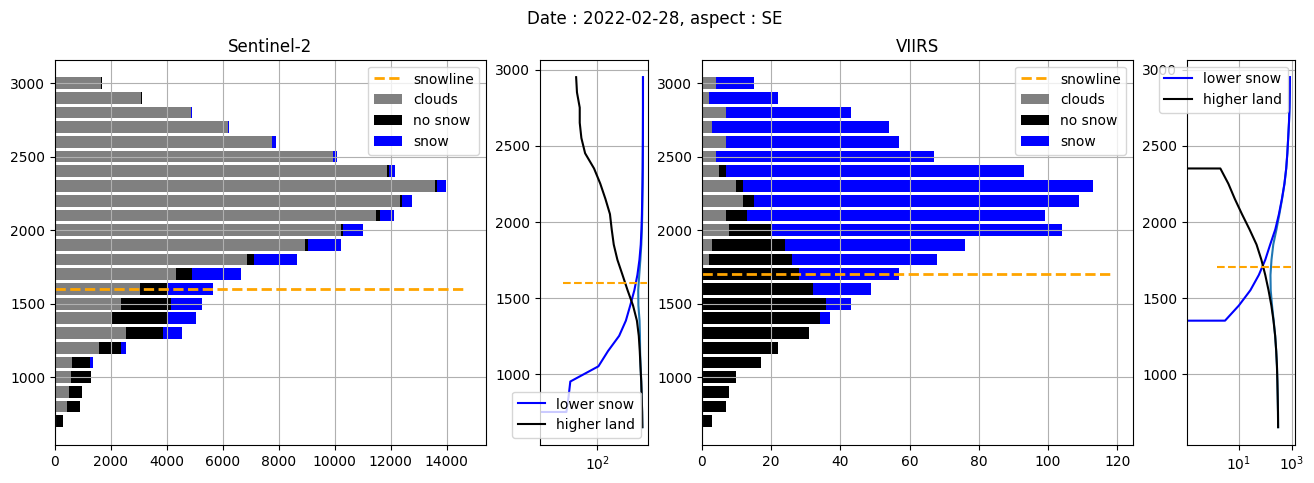

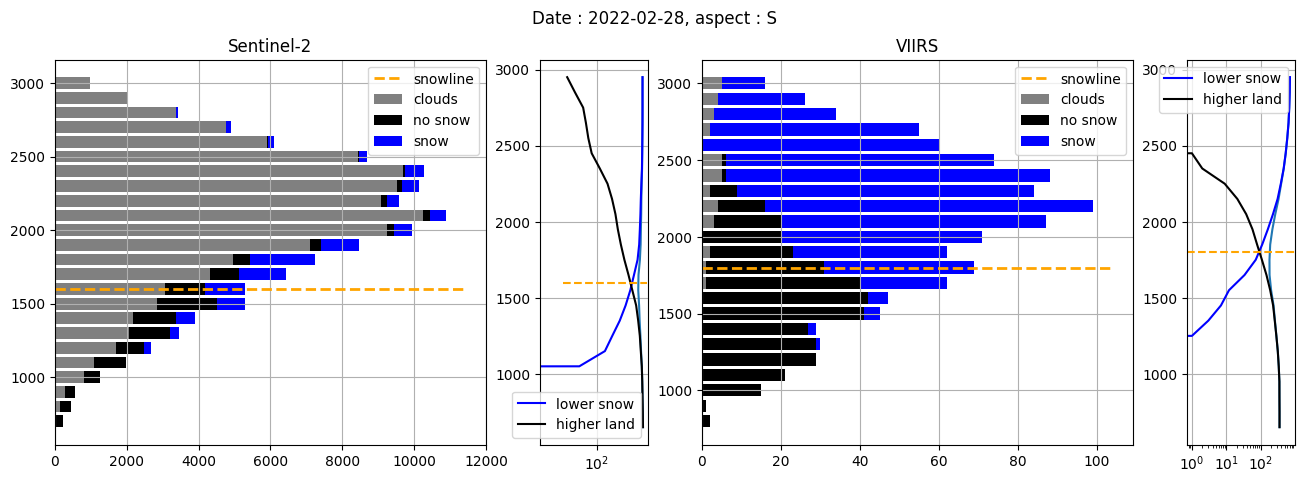

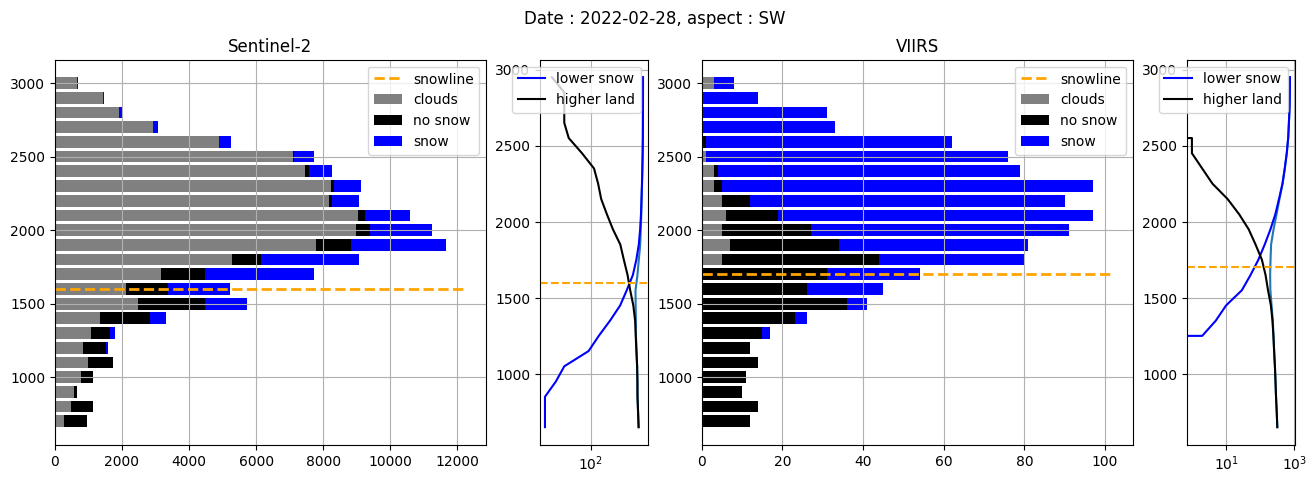

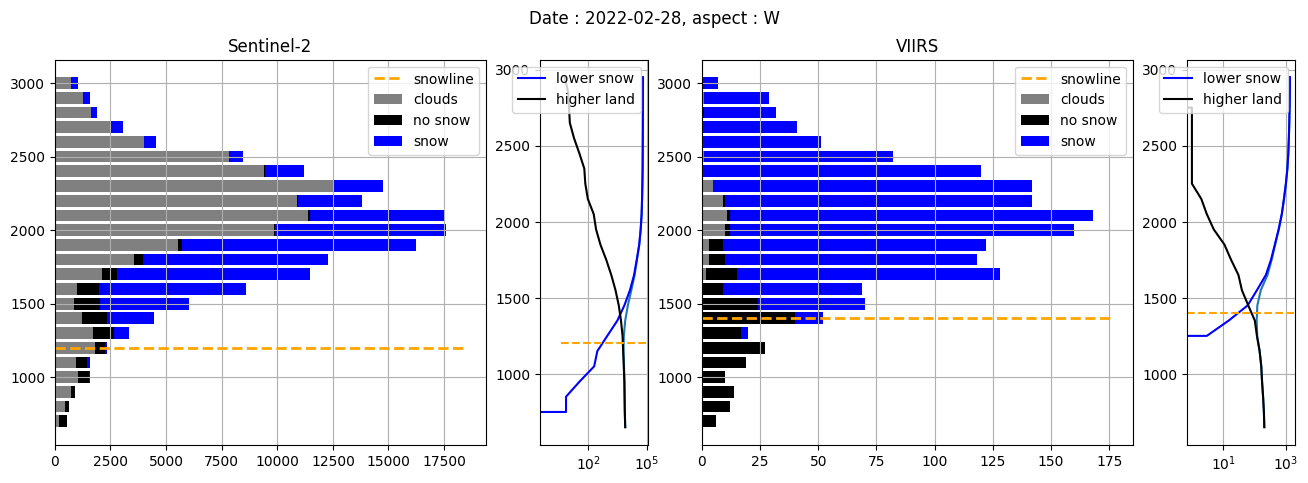

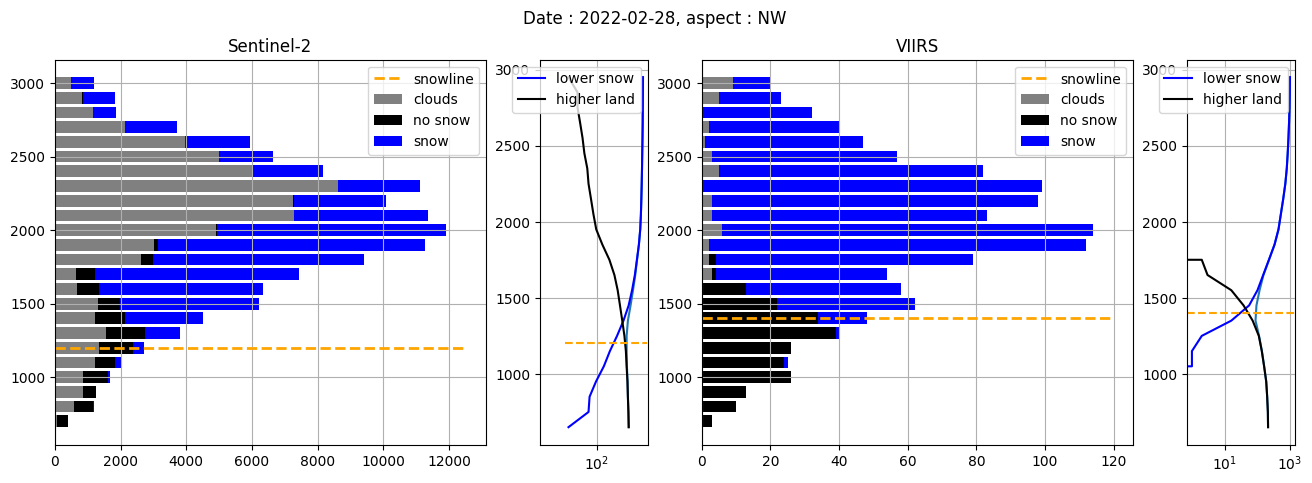

In [ ]:
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from matplotlib.axes import Axes


def find_snowline_from_snow_penalization_new(snowline_parametrization_dataset: xr.Dataset) -> xr.DataArray:
    alt_index = snowline_parametrization_dataset.data_vars["snowline_penalization"].argmin("elevation_min")
    altitude_step = 100
    snowline = snowline_parametrization_dataset.coords["elevation_min"].values[alt_index]
    # Recover the center of altitude bins used for snowline calculation
    snowline = snowline + altitude_step // 2
    return snowline


date = "2022-02-28"
# aspect = "S"
result_s2 = xr.open_dataset("result_s2_thr05.nc")
result_viirs = xr.open_dataset("result_viirs_thr05.nc")
for aspect in result_s2.coords["aspect_bins"].values:
    grid_spec = GridSpec(nrows=1, ncols=4, hspace=0.25, width_ratios=(1, 0.25, 1, 0.25))
    fig = plt.figure(
        figsize=(16, 5),
    )
    ax_s2_hist = fig.add_subplot(grid_spec[0])
    ax_viirs_hist = fig.add_subplot(grid_spec[2])
    ax_s2_pen = fig.add_subplot(grid_spec[1])
    ax_viirs_pen = fig.add_subplot(grid_spec[3])

    res_s2 = result_s2.sel(time=date, aspect_bins=aspect)
    res_viirs = result_viirs.sel(time=date, aspect_bins=aspect)
    plot_snow_cloud_vs_elevation_bars(plot_data=res_s2, ax=ax_s2_hist)
    plot_snow_cloud_vs_elevation_bars(plot_data=res_viirs, ax=ax_viirs_hist)
    # elvations = snowline_s2_ds.coords['altitude_min']
    # penalization_s2 = snowline_s2_ds.data_vars["snowline_penalization"].sel(aspect=aspect, time=date)
    # penalization_viirs = snowline_viirs_ds.data_vars["snowline_penalization"].sel(aspect=aspect, time=date)
    # ax_s2_pen.semilogx(penalization_s2, snowline_s2_ds.coords["altitude_min"])
    # ax_viirs_pen.semilogx(penalization_viirs, snowline_viirs_ds.coords["altitude_min"])
    ax_s2_pen.semilogx(res_s2.data_vars["snowline_penalization"], res_s2.coords["elevation_min"])
    ax_viirs_pen.semilogx(res_viirs.data_vars["snowline_penalization"], res_s2.coords["elevation_min"])
    ax_s2_pen.semilogx(res_s2.data_vars["lower_snow_sum"], res_s2.coords["elevation_min"], color="blue", label="lower snow")
    ax_viirs_pen.semilogx(
        res_viirs.data_vars["lower_snow_sum"], res_viirs.coords["elevation_min"], color="blue", label="lower snow"
    )
    ax_s2_pen.semilogx(res_s2.data_vars["higher_land_sum"], res_s2.coords["elevation_min"], color="black", label="higher land")

    ax_viirs_pen.semilogx(
        res_viirs.data_vars["higher_land_sum"], res_viirs.coords["elevation_min"], color="black", label="higher land"
    )
    ax_s2_pen.hlines(
        find_snowline_from_snow_penalization_new(res_s2),
        xmin=ax_s2_pen.get_xlim()[0],
        xmax=ax_s2_pen.get_xlim()[1],
        color="orange",
        linestyle="dashed",
    )
    ax_viirs_pen.hlines(
        find_snowline_from_snow_penalization_new(res_viirs),
        xmin=ax_viirs_pen.get_xlim()[0],
        xmax=ax_viirs_pen.get_xlim()[1],
        color="orange",
        linestyle="dashed",
    )

    ax_s2_hist.hlines(
        sl_s2_precalc.sel(aspect=aspect, time=date),
        xmin=ax_s2_hist.get_xlim()[0],
        xmax=ax_s2_hist.get_xlim()[1],
        color="orange",
        linestyle="dashed",
        linewidth=2,
        label="snowline",
    )
    ax_viirs_hist.hlines(
        sl_viirs_precalc.sel(aspect=aspect, time=date),
        xmin=ax_viirs_hist.get_xlim()[0],
        xmax=ax_viirs_hist.get_xlim()[1],
        color="orange",
        linestyle="dashed",
        linewidth=2,
        label="snowline",
    )
    axs = (ax_s2_hist, ax_s2_pen, ax_viirs_hist, ax_viirs_pen)
    [ax.legend() for ax in axs]
    [ax.grid() for ax in axs]
    ax_s2_hist.set_title("Sentinel-2")
    ax_viirs_hist.set_title("VIIRS")
    fig.suptitle(f"Date : {date}, aspect : {aspect}")
plt.show()

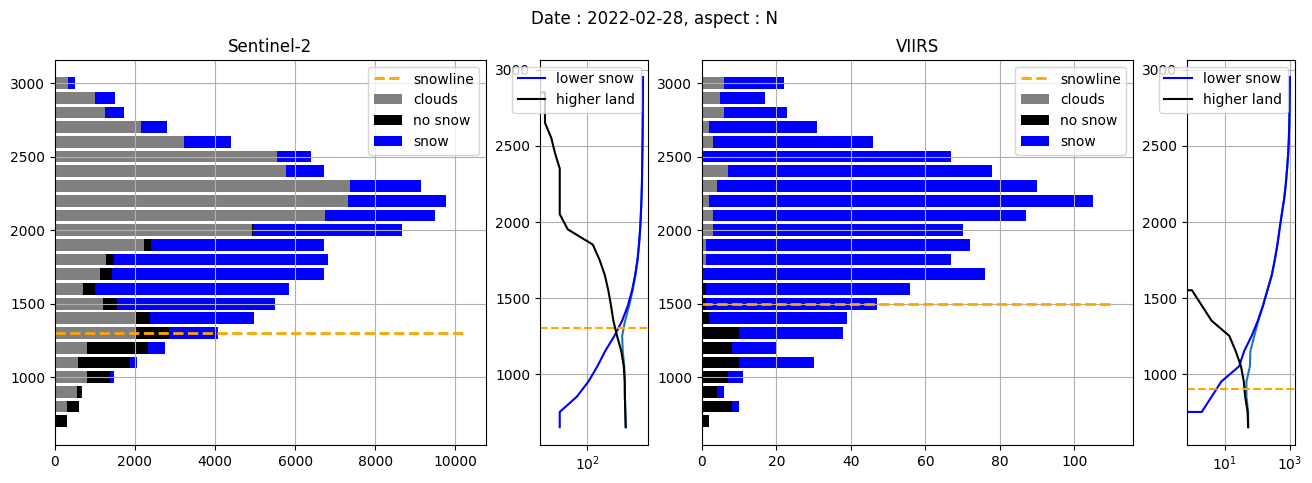

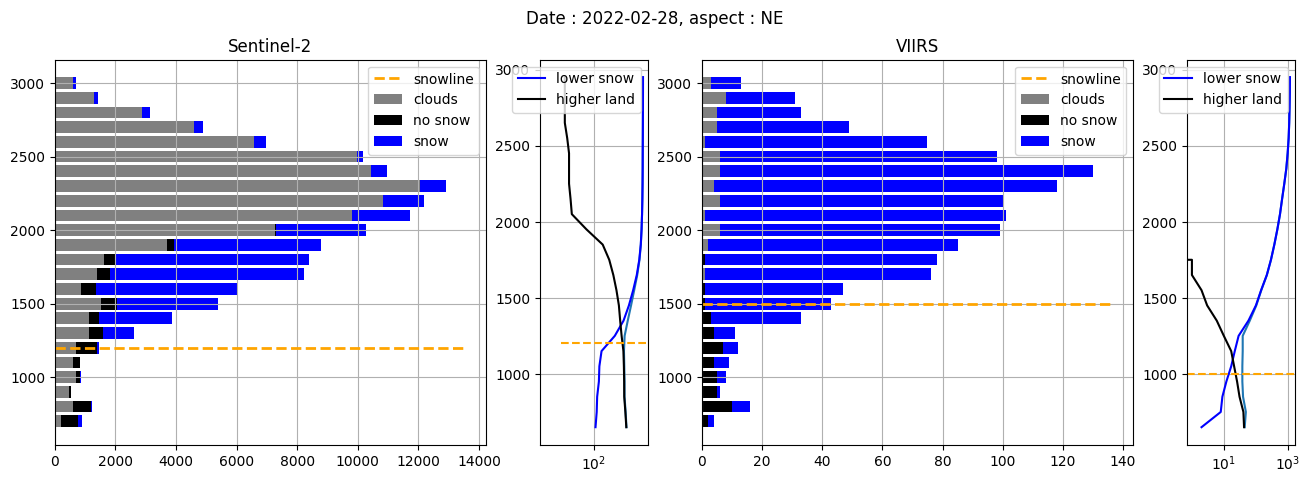

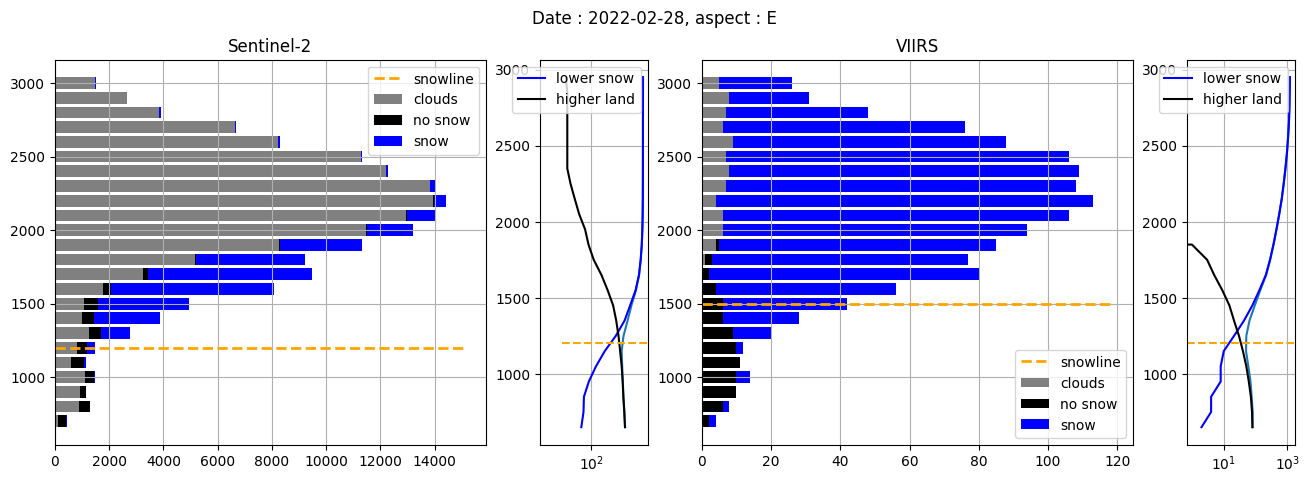

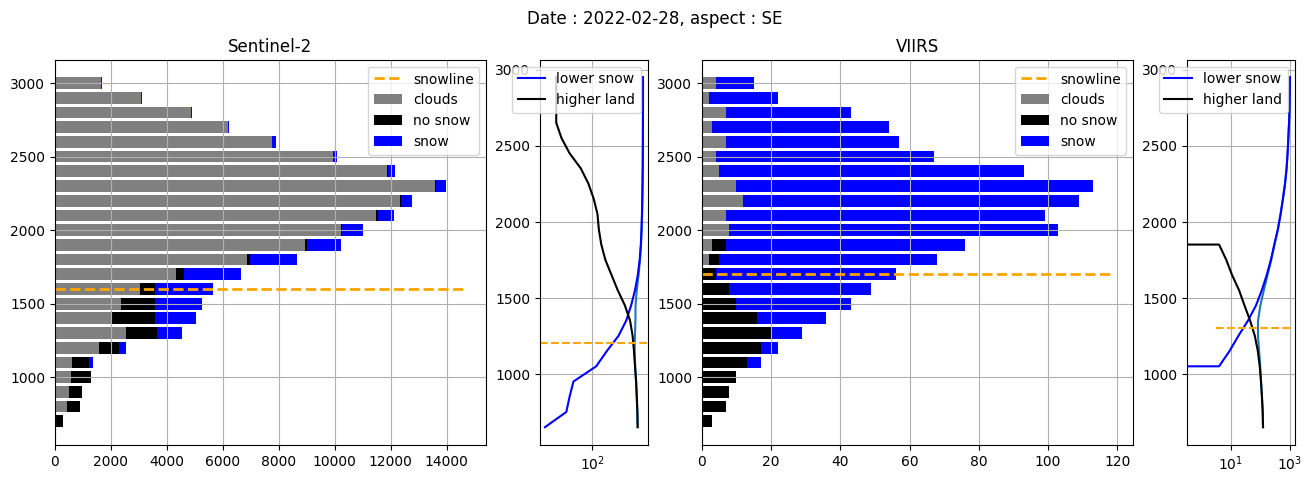

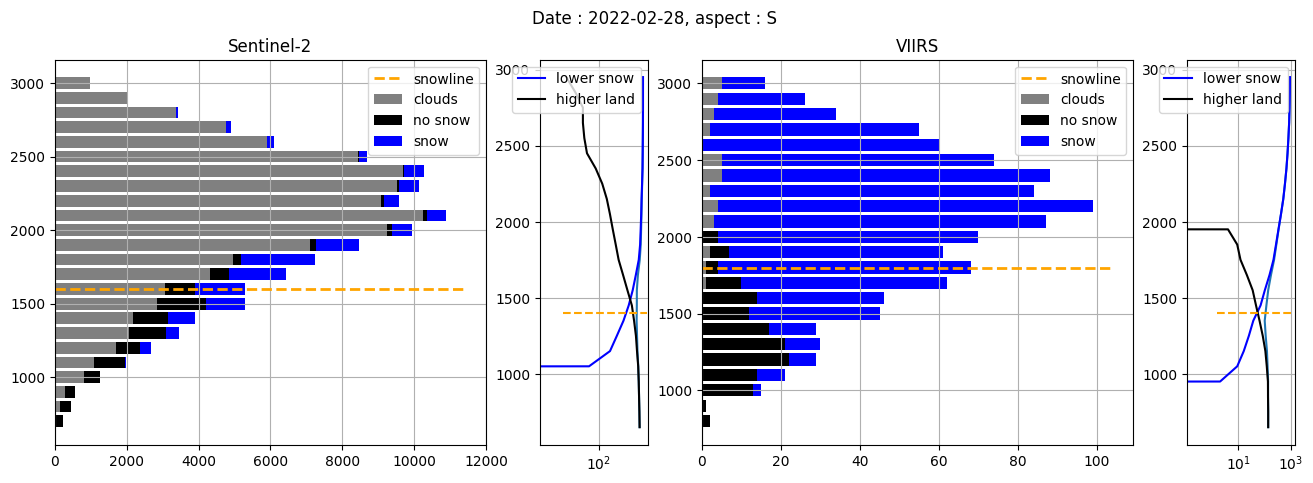

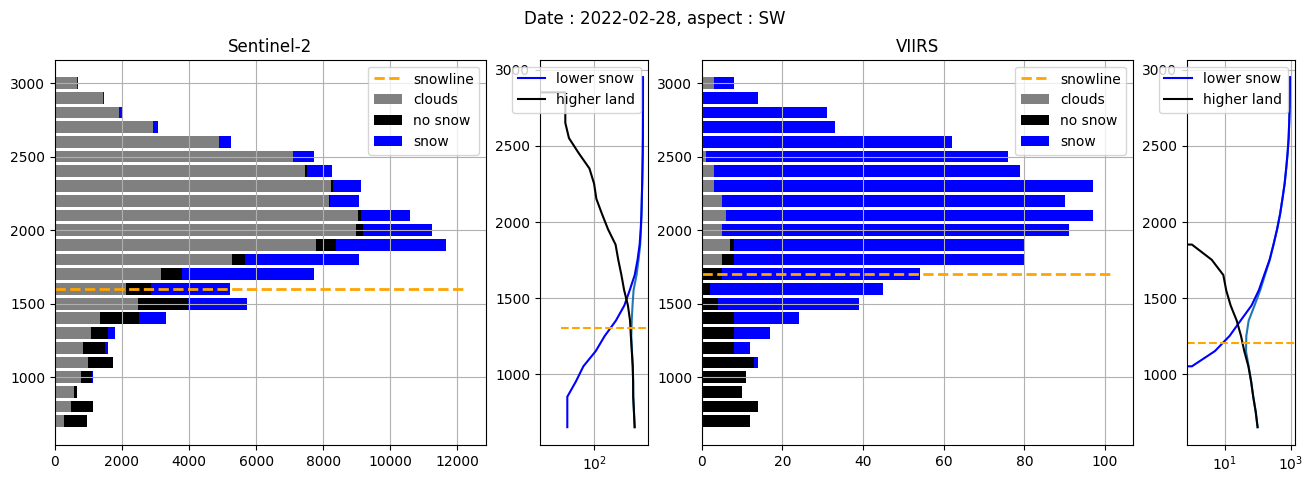

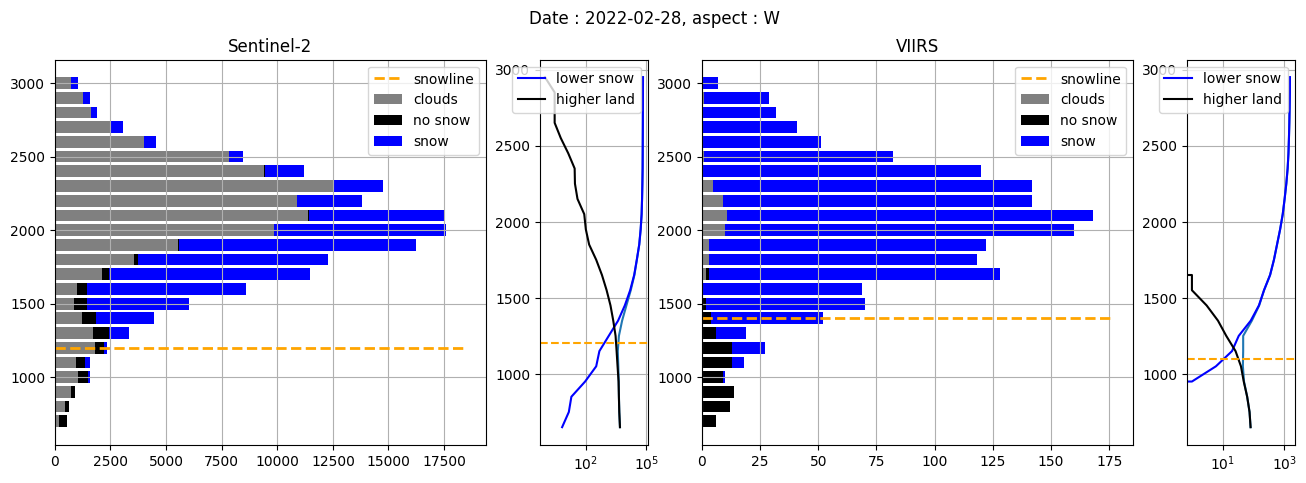

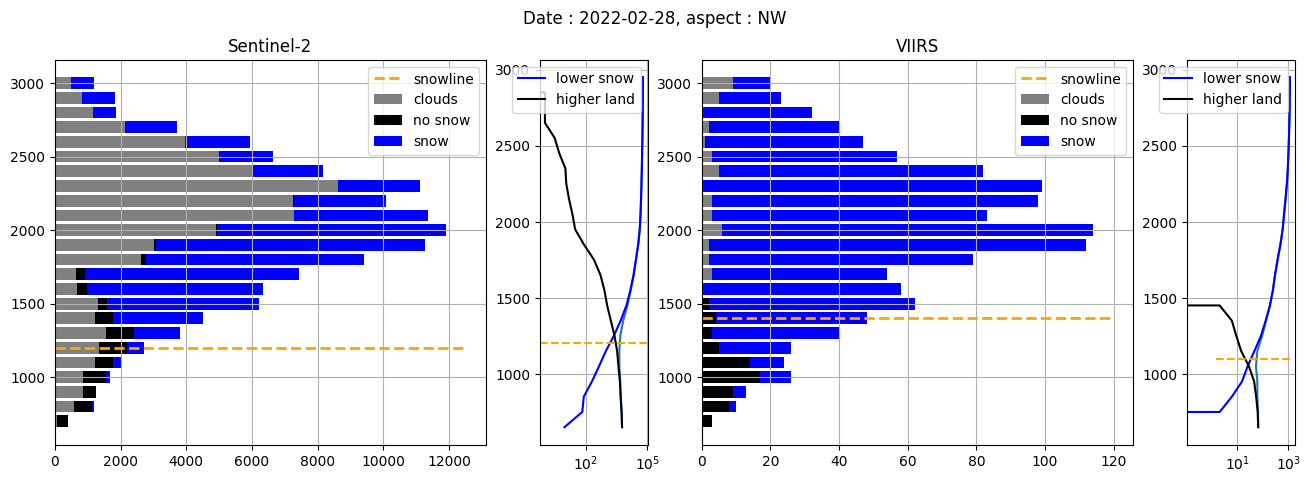

In [ ]:
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from matplotlib.axes import Axes


def find_snowline_from_snow_penalization_new(snowline_parametrization_dataset: xr.Dataset) -> xr.DataArray:

    alt_index = snowline_parametrization_dataset.data_vars["snowline_penalization"].argmin("elevation_min")
    altitude_step = 100
    snowline = snowline_parametrization_dataset.coords["elevation_min"].values[alt_index]
    # Recover the center of altitude bins used for snowline calculation
    snowline = snowline + altitude_step // 2
    return snowline


date = "2022-02-28"
# aspect = "S"
result_s2 = xr.open_dataset("result_s2_thr001.nc")
result_viirs = xr.open_dataset("result_viirs_thr001.nc")
for aspect in result_s2.coords["aspect_bins"].values:
    grid_spec = GridSpec(nrows=1, ncols=4, hspace=0.25, width_ratios=(1, 0.25, 1, 0.25))
    fig = plt.figure(
        figsize=(16, 5),
    )
    ax_s2_hist = fig.add_subplot(grid_spec[0])
    ax_viirs_hist = fig.add_subplot(grid_spec[2])
    ax_s2_pen = fig.add_subplot(grid_spec[1])
    ax_viirs_pen = fig.add_subplot(grid_spec[3])

    res_s2 = result_s2.sel(time=date, aspect_bins=aspect)
    res_viirs = result_viirs.sel(time=date, aspect_bins=aspect)
    plot_snow_cloud_vs_elevation_bars(plot_data=res_s2, ax=ax_s2_hist)
    plot_snow_cloud_vs_elevation_bars(plot_data=res_viirs, ax=ax_viirs_hist)
    # elvations = snowline_s2_ds.coords['altitude_min']
    # penalization_s2 = snowline_s2_ds.data_vars["snowline_penalization"].sel(aspect=aspect, time=date)
    # penalization_viirs = snowline_viirs_ds.data_vars["snowline_penalization"].sel(aspect=aspect, time=date)
    # ax_s2_pen.semilogx(penalization_s2, snowline_s2_ds.coords["altitude_min"])
    # ax_viirs_pen.semilogx(penalization_viirs, snowline_viirs_ds.coords["altitude_min"])
    ax_s2_pen.semilogx(res_s2.data_vars["snowline_penalization"], res_s2.coords["elevation_min"])
    ax_viirs_pen.semilogx(res_viirs.data_vars["snowline_penalization"], res_s2.coords["elevation_min"])
    ax_s2_pen.semilogx(res_s2.data_vars["lower_snow_sum"], res_s2.coords["elevation_min"], color="blue", label="lower snow")
    ax_viirs_pen.semilogx(
        res_viirs.data_vars["lower_snow_sum"], res_viirs.coords["elevation_min"], color="blue", label="lower snow"
    )
    ax_s2_pen.semilogx(res_s2.data_vars["higher_land_sum"], res_s2.coords["elevation_min"], color="black", label="higher land")

    ax_viirs_pen.semilogx(
        res_viirs.data_vars["higher_land_sum"], res_viirs.coords["elevation_min"], color="black", label="higher land"
    )
    ax_s2_pen.hlines(
        find_snowline_from_snow_penalization_new(res_s2),
        xmin=ax_s2_pen.get_xlim()[0],
        xmax=ax_s2_pen.get_xlim()[1],
        color="orange",
        linestyle="dashed",
    )
    ax_viirs_pen.hlines(
        find_snowline_from_snow_penalization_new(res_viirs),
        xmin=ax_viirs_pen.get_xlim()[0],
        xmax=ax_viirs_pen.get_xlim()[1],
        color="orange",
        linestyle="dashed",
    )

    ax_s2_hist.hlines(
        sl_s2_precalc.sel(aspect=aspect, time=date),
        xmin=ax_s2_hist.get_xlim()[0],
        xmax=ax_s2_hist.get_xlim()[1],
        color="orange",
        linestyle="dashed",
        linewidth=2,
        label="snowline",
    )
    ax_viirs_hist.hlines(
        sl_viirs_precalc.sel(aspect=aspect, time=date),
        xmin=ax_viirs_hist.get_xlim()[0],
        xmax=ax_viirs_hist.get_xlim()[1],
        color="orange",
        linestyle="dashed",
        linewidth=2,
        label="snowline",
    )
    axs = (ax_s2_hist, ax_s2_pen, ax_viirs_hist, ax_viirs_pen)
    [ax.legend() for ax in axs]
    [ax.grid() for ax in axs]
    ax_s2_hist.set_title("Sentinel-2")
    ax_viirs_hist.set_title("VIIRS")
    fig.suptitle(f"Date : {date}, aspect : {aspect}")
plt.show()